In [1]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 43.7 MB/s eta 0:00:00


In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
from gensim.models import Word2Vec
import re

In [3]:
data = pd.read_csv("IMDB Dataset.csv")

In [4]:
data.head(5)

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [5]:
data.describe()

,review,sentiment
count,50000,50000
unique,49582,2
top,Loved today's show!!! It was a variety and not...,positive
freq,5,25000


In [6]:
print(f"=== 1. Số samples ===\n{len(data)}\n")

print(f"=== 2. Số classes ===\n{data['sentiment'].nunique()} ({data['sentiment'].unique().tolist()})\n")

print("=== 3. Phân phối class (Class distribution) ===")
print(data['sentiment'].value_counts())
print()

print("=== 4. Thống kê độ dài văn bản (Document length in words) ===")
word_counts = data['review'].apply(lambda x: len(str(x).split()))
print(word_counts.describe())
print()

print(f"=== 5. Số lượng văn bản trùng lặp (Duplicate documents) ===\n{data['review'].duplicated().sum()}\n")

print(f"=== 6. Số lượng văn bản bị thiếu (Missing text) ===\n{data['review'].isnull().sum()}\n")

print(f"=== 7. Số lượng nhãn bị thiếu (Missing labels) ===\n{data['sentiment'].isnull().sum()}")

=== 1. Số samples ===
50000

=== 2. Số classes ===
2 (['positive', 'negative'])

=== 3. Phân phối class (Class distribution) ===
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

=== 4. Thống kê độ dài văn bản (Document length in words) ===
count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: review, dtype: float64

=== 5. Số lượng văn bản trùng lặp (Duplicate documents) ===
418

=== 6. Số lượng văn bản bị thiếu (Missing text) ===
0

=== 7. Số lượng nhãn bị thiếu (Missing labels) ===
0


##dataset này có số lượng 2 class là bằng nhau (=25000) => dataset balanced


In [16]:

# ============================================
# EXPERIMENT 2: BASELINE TF-IDF + LOGISTIC REGRESSION
# Dataset: IMDB Dataset.csv
# ============================================

import pandas as pd
import time
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Đọc dữ liệu
df = pd.read_csv("/content/IMDB Dataset.csv")

# Kiểm tra tên cột và dữ liệu
print("Kích thước dataset:", df.shape)
print("Tên cột:", df.columns.tolist())
print(df.head())

# 2. Làm sạch dữ liệu cơ bản
df = df.dropna(subset=["review", "sentiment"])
df = df.drop_duplicates(subset=["review"])

X = df["review"].astype(str)
y = df["sentiment"].astype(str).str.lower().str.strip()

# 3. Chia train/test trước khi fit TF-IDF
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nSố mẫu train:", len(X_train))
print("Số mẫu test:", len(X_test))

# 4. Xây dựng baseline
model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("lr", LogisticRegression(max_iter=1000))
])

# 5. Huấn luyện và đo thời gian
start_time = time.perf_counter()

model.fit(X_train, y_train)

training_time = time.perf_counter() - start_time

# 6. Lấy kích thước vocabulary
vocabulary_size = len(
    model.named_steps["tfidf"].vocabulary_
)

# 7. Dự đoán trên tập test
y_pred = model.predict(X_test)

# 8. Tính các metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    pos_label="positive",
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    pos_label="positive",
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    pos_label="positive",
    zero_division=0
)

# 9. In kết quả
print("\n========== BASELINE RESULTS ==========")
print(f"Training time : {training_time:.2f} seconds")
print(f"Vocabulary    : {vocabulary_size}")
print(f"Accuracy      : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision     : {precision:.4f} ({precision*100:.2f}%)")
print(f"Recall        : {recall:.4f} ({recall*100:.2f}%)")
print(f"F1-score      : {f1:.4f} ({f1*100:.2f}%)")

# 10. Tạo bảng kết quả để đưa vào báo cáo
results = pd.DataFrame([{
    "Model": "TF-IDF + LR",
    "Training time (s)": round(training_time, 2),
    "Vocabulary size": vocabulary_size,
    "Accuracy": round(accuracy, 4),
    "Precision": round(precision, 4),
    "Recall": round(recall, 4),
    "F1": round(f1, 4)
}])

display(results)


Kích thước dataset: (50000, 2)
Tên cột: ['review', 'sentiment']
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive

Số mẫu train: 39665
Số mẫu test: 9917

========== BASELINE RESULTS ==========
Training time : 13.73 seconds
Vocabulary    : 92953
Accuracy      : 0.8971 (89.71%)
Precision     : 0.8880 (88.80%)
Recall        : 0.9098 (90.98%)
F1-score      : 0.8988 (89.88%)


,Model,Training time (s),Vocabulary size,Accuracy,Precision,Recall,F1
0,TF-IDF + LR,13.73,92953,0.8971,0.888,0.9098,0.8988


In [18]:
# =========================================
# 4. MODEL B: AVERAGE WORD2VEC + LR
# =========================================

# Tokenize đơn giản, không dùng nhãn để tạo embedding
def tokenize(text):
    return re.findall(r"\b[a-zA-Z]+\b", text.lower())

start = time.perf_counter()

train_tokens = [tokenize(text) for text in X_train]
test_tokens = [tokenize(text) for text in X_test]

# Học Word2Vec chỉ từ văn bản train
w2v = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    workers=2,
    sg=1,
    epochs=5,
    seed=42
)

# Lấy trung bình vector của các từ trong mỗi review
def average_word_vectors(tokenized_docs, w2v_model):
    vectors = []

    for tokens in tokenized_docs:
        word_vectors = [
            w2v_model.wv[word]
            for word in tokens
            if word in w2v_model.wv
        ]

        if len(word_vectors) > 0:
            vectors.append(np.mean(word_vectors, axis=0))
        else:
            # Review không có từ trong vocabulary
            vectors.append(np.zeros(w2v_model.vector_size))

    return np.array(vectors)

X_train_w2v = average_word_vectors(train_tokens, w2v)
X_test_w2v = average_word_vectors(test_tokens, w2v)

lr_w2v = LogisticRegression(max_iter=1000)
lr_w2v.fit(X_train_w2v, y_train)

time_b = time.perf_counter() - start

evaluate_model(
    "Average Word2Vec + Logistic Regression",
    lr_w2v, X_train_w2v, X_test_w2v,
    y_train, y_test, time_b
)


In [23]:

# Khởi tạo danh sách kết quả chứa cả hai mô hình
results = []

# Thêm thông tin của Model A: TF-IDF + LR
results.append({
    "Model": "TF-IDF + LR",
    "Training time (s)": round(training_time, 2),
    "Vocabulary size": vocabulary_size,
    "Accuracy": round(accuracy, 4),
    "Precision": round(precision, 4),
    "Recall": round(recall, 4),
    "F1": round(f1, 4)
})

# Thêm thông tin của Model B: Average Word2Vec + LR
results.append({
    "Model": "Average Word2Vec + LR",
    "Training time (s)": round(time_b, 2),
    "Vocabulary size": len(w2v.wv.key_to_index),
    "Accuracy": round(accuracy_w2v, 4),
    "Precision": round(precision_w2v, 4),
    "Recall": round(recall_w2v, 4),
    "F1": round(f1_w2v, 4)
})

# Tạo DataFrame và hiển thị bảng so sánh
results_df = pd.DataFrame(results)
display(results_df)


,Model,Training time (s),Vocabulary size,Accuracy,Precision,Recall,F1
0,TF-IDF + LR,13.73,92953,0.8971,0.8880,0.9098,0.8988
1,Average Word2Vec + LR,331.42,56482,0.8375,0.8376,0.8375,0.8375


In [24]:

# MỤC 17: WORD ORDER / NEGATION

sentences = [
    "this movie is good",
    "this movie is not good"
]

def sentence_to_avg_vector(sentence, w2v_model):
    tokens = tokenize(sentence)

    vectors = [
        w2v_model.wv[word]
        for word in tokens
        if word in w2v_model.wv
    ]

    if not vectors:
        return np.zeros(w2v_model.vector_size)

    return np.mean(vectors, axis=0)

for i, sentence in enumerate(sentences, start=1):
    tokens = tokenize(sentence)
    known_tokens = [
        word for word in tokens
        if word in w2v.wv
    ]

    vector = sentence_to_avg_vector(sentence, w2v)

    print(f"\nS{i}: {sentence}")
    print("Tokens:", tokens)
    print("Tokens in vocabulary:", known_tokens)
    print("Vector shape:", vector.shape)
    print("First 10 vector values:", vector[:10])



S1: this movie is good
Tokens: ['this', 'movie', 'is', 'good']
Tokens in vocabulary: ['this', 'movie', 'is', 'good']
Vector shape: (100,)
First 10 vector values: [-0.09883117  0.34596515 -0.17761964  0.02593281  0.21836637  0.07005171
  0.03830495  0.1843734  -0.22100826 -0.02704252]

S2: this movie is not good
Tokens: ['this', 'movie', 'is', 'not', 'good']
Tokens in vocabulary: ['this', 'movie', 'is', 'not', 'good']
Vector shape: (100,)
First 10 vector values: [-0.06105974  0.33292067 -0.14372234  0.10972355  0.22466984  0.02740154
 -0.01755154  0.23943874 -0.2701438  -0.02819281]


In [25]:

# MỤC 18: UNIGRAM VS UNIGRAM + BIGRAM

import time
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

ngram_results = []
ngram_models = {}

for name, ngram_range in [
    ("Unigram", (1, 1)),
    ("Unigram + Bigram", (1, 2))
]:
    model = Pipeline([
        (
            "tfidf",
            TfidfVectorizer(ngram_range=ngram_range)
        ),
        (
            "lr",
            LogisticRegression(max_iter=1000)
        )
    ])

    start = time.perf_counter()
    model.fit(X_train, y_train)
    elapsed = time.perf_counter() - start

    y_pred = model.predict(X_test)

    vocabulary_size = len(
        model.named_steps["tfidf"].vocabulary_
    )

    f1 = f1_score(
        y_test, y_pred,
        pos_label="positive",
        zero_division=0
    )

    ngram_results.append({
        "Features": name,
        "Vocabulary size": vocabulary_size,
        "F1": f1,
        "Training time (s)": elapsed
    })

    ngram_models[name] = model

ngram_df = pd.DataFrame(ngram_results)
display(ngram_df.round(4))

ngram_df.to_csv(
    "/content/experiment_5_ngram_results.csv",
    index=False
)


,Features,Vocabulary size,F1,Training time (s)
0,Unigram,92953,0.8988,15.6937
1,Unigram + Bigram,2111143,0.9018,87.1183


Confusion matrix:
[[4365  575]
 [ 418 4559]]


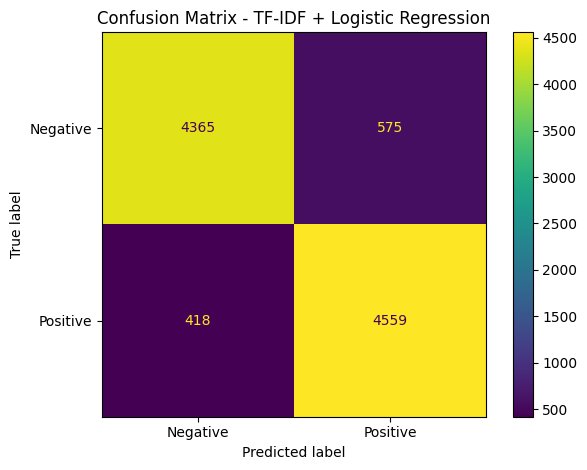

Đã lưu confusion_matrix.png


In [28]:
# MỤC 20: CONFUSION MATRIX

import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Đánh giá baseline TF-IDF + Logistic Regression (đổi model_a thành model)
y_pred = model.predict(X_test)

labels = ["negative", "positive"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

print("Confusion matrix:")
print(cm)

display_labels = ["Negative", "Positive"]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

disp.plot(values_format="d")
plt.title("Confusion Matrix - TF-IDF + Logistic Regression")
plt.tight_layout()
plt.savefig(
    "/content/confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print("Đã lưu confusion_matrix.png")

In [27]:

# MỤC 21: ERROR ANALYSIS

error_df = pd.DataFrame({
    "Text": X_test.reset_index(drop=True),
    "True": y_test.reset_index(drop=True),
    "Predicted": pd.Series(y_pred).reset_index(drop=True)
})

error_df["Correct"] = (
    error_df["True"] == error_df["Predicted"]
)

correct_samples = error_df[error_df["Correct"]].head(3)
incorrect_samples = error_df[~error_df["Correct"]].head(3)

print("=== 3 CORRECTLY CLASSIFIED SAMPLES ===")
display(correct_samples[["Text", "True", "Predicted"]])

print("=== 3 INCORRECTLY CLASSIFIED SAMPLES ===")
display(incorrect_samples[["Text", "True", "Predicted"]])

# Lưu mẫu để Quân tự phân tích
correct_samples.to_csv(
    "/content/correct_samples.csv", index=False
)

incorrect_samples.to_csv(
    "/content/incorrect_samples.csv", index=False
)


=== 3 CORRECTLY CLASSIFIED SAMPLES ===


,Text,True,Predicted
0,My wife and I watched this after DVR'ing it of...,negative,negative
1,I was surprised how much I enjoyed this. Sure ...,positive,positive
2,Such a delightful movie! Very heart warming. O...,positive,positive


=== 3 INCORRECTLY CLASSIFIED SAMPLES ===


,Text,True,Predicted
15,"This isn't exactly a great film, but I admire ...",positive,negative
24,Despite being a huge fan of Fred Astaire and G...,negative,positive
35,"Well, well....Roeg touched a bit of a nerve th...",positive,negative


In [30]:

# MỤC 22: INSPECT MODEL WEIGHTS

import pandas as pd

# Đổi model_a thành model
tfidf = model.named_steps["tfidf"]
lr = model.named_steps["lr"]

feature_names = tfidf.get_feature_names_out()
weights = lr.coef_[0]

# coef_[0] biểu diễn chiều hướng tới classes_[1]
positive_label = lr.classes_[1]

weights_df = pd.DataFrame({
    "Feature": feature_names,
    "Weight": weights
})

# Xác định đúng chiều Positive
if positive_label == "positive":
    positive_features = weights_df.nlargest(15, "Weight")
    negative_features = weights_df.nsmallest(15, "Weight")
else:
    positive_features = weights_df.nsmallest(15, "Weight")
    negative_features = weights_df.nlargest(15, "Weight")

print("=== TOP POSITIVE FEATURES ===")
display(
    positive_features.sort_values(
        "Weight", ascending=False
    ).reset_index(drop=True)
)

print("=== TOP NEGATIVE FEATURES ===")
display(
    negative_features.sort_values(
        "Weight", ascending=True
    ).reset_index(drop=True)
)

positive_features.to_csv(
    "/content/top_positive_features.csv", index=False
)

negative_features.to_csv(
    "/content/top_negative_features.csv", index=False
)


=== TOP POSITIVE FEATURES ===


,Feature,Weight
0,great,9.984328
1,excellent,6.949238
2,and,5.473338
3,best,5.234093
4,wonderful,5.197444
5,perfect,5.152569
6,the best,4.877048
7,love,4.870243
8,amazing,4.738889
9,well,4.546295


=== TOP NEGATIVE FEATURES ===


,Feature,Weight
0,bad,-10.702620
1,worst,-9.134875
2,awful,-7.599326
3,the worst,-7.308946
4,boring,-7.021869
5,poor,-6.537780
6,terrible,-6.246374
7,waste,-6.115483
8,nothing,-5.899627
9,no,-5.619435


In [32]:

# MỤC 23: APPLICATION

def predict_sentiment(review):
    # Đổi model_a thành model
    prediction = model.predict([review])[0]

    probability = model.predict_proba([review])[0]
    classes = model.named_steps["lr"].classes_

    confidence = probability[
        list(classes).index(prediction)
    ]

    return {
        "Review": review,
        "Predicted sentiment": prediction,
        "Confidence": round(float(confidence), 4)
    }

sample_review = (
    "The movie was engaging, beautifully acted, "
    "and enjoyable from beginning to end."
)

display(pd.DataFrame([
    predict_sentiment(sample_review)
]))


,Review,Predicted sentiment,Confidence
0,"The movie was engaging, beautifully acted, and...",positive,0.8279
